In [ ]:
#importing data
import pandas as pd

df = pd.read_csv("creditworthiness_raw_sample.csv")

print(df)

    business_id  annual_revenue_usd  monthly_expenses_usd  requested_loan_usd  \
0        SB0001              103094               6165.21              127618   
1        SB0002              702211              35643.23              134164   
2        SB0003              597750              32920.08               37395   
3        SB0004              409018              26270.86              134549   
4        SB0005              403888              23529.68               21817   
..          ...                 ...                   ...                 ...   
115      SB0116              522648              16319.72              118790   
116      SB0117               57604               2828.85              127812   
117      SB0118              147322              10997.67                7586   
118      SB0119              239796              16794.16              101216   
119      SB0120              125213               7948.25               20825   

     business_age_years  ow

In [ ]:
#finding missing data
print(df.isnull().sum())

business_id              0
annual_revenue_usd       0
monthly_expenses_usd     5
requested_loan_usd       0
business_age_years       0
owner_credit_score       4
late_payments_12m        0
cash_reserves_usd        0
industry                 3
tax_returns_available    4
monthly_transactions     5
default_within_12m       0
dtype: int64


In [ ]:
#using fillna
df["monthly_expenses_usd"] = df["monthly_expenses_usd"].fillna(df["monthly_expenses_usd"].mean())

df["owner_credit_score"] = df["owner_credit_score"].fillna(df["owner_credit_score"].mean())

df["monthly_transactions"] = df["monthly_transactions"].fillna(df["monthly_transactions"].mean())

In [ ]:
#for missing values
df["industry"] = df["industry"].fillna(df["industry"].mode()[0])

df["tax_returns_available"] = df["tax_returns_available"].fillna(df["tax_returns_available"].mode()[0])

In [ ]:
# Numerical columns: replace NaN with mean
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Text columns: replace NaN with mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values
print(df.isnull().sum())

business_id              0
annual_revenue_usd       0
monthly_expenses_usd     0
requested_loan_usd       0
business_age_years       0
owner_credit_score       0
late_payments_12m        0
cash_reserves_usd        0
industry                 0
tax_returns_available    0
monthly_transactions     0
default_within_12m       0
dtype: int64


In [ ]:
print(df.isnull().sum())

business_id              0
annual_revenue_usd       0
monthly_expenses_usd     0
requested_loan_usd       0
business_age_years       0
owner_credit_score       0
late_payments_12m        0
cash_reserves_usd        0
industry                 0
tax_returns_available    0
monthly_transactions     0
default_within_12m       0
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer
import numpy as np
# Select input features
X = df.iloc[:, :-1].values

# Create imputer
imputer = SimpleImputer(
    missing_values=np.nan,
    strategy="mean"
)

# Fit and transform numerical columns
X[:, 1:3] = imputer.fit_transform(X[:, 1:3])

print(X)

[['SB0001' 103094.0 6165.21 ... 'Professional_Services' 'Yes' 1778.0]
 ['SB0002' 702211.0 35643.23 ... 'Food_Service' 'Yes' 691.0]
 ['SB0003' 597750.0 32920.08 ... 'Transport' 'Yes' 1452.0]
 ...
 ['SB0118' 147322.0 10997.67 ... 'Food_Service' 'Yes' 680.0]
 ['SB0119' 239796.0 16794.16 ... 'Professional_Services' 'Yes' 1506.0]
 ['SB0120' 125213.0 7948.25 ... 'Food_Service' 'No' 740.0]]


In [ ]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Import dataset
df = pd.read_csv("creditworthiness_raw_sample.csv")

# Separate input features
X = df.iloc[:, :-1].values

# Encode the first column (setting sparse_output=False to avoid sparse-dense mixing errors)
ct = ColumnTransformer(
    transformers=[
        ("encoder", OneHotEncoder(sparse_output=False, handle_unknown="ignore"), [0])
    ],
    remainder="passthrough"
)

X = np.array(ct.fit_transform(X))

print(X)

[[1.0 0.0 0.0 ... 'Professional_Services' 'Yes' 1778.0]
 [0.0 1.0 0.0 ... 'Food_Service' 'Yes' 691.0]
 [0.0 0.0 1.0 ... 'Transport' 'Yes' 1452.0]
 ...
 [0.0 0.0 0.0 ... 'Food_Service' nan 680.0]
 [0.0 0.0 0.0 ... 'Professional_Services' 'Yes' 1506.0]
 [0.0 0.0 0.0 ... 'Food_Service' 'No' 740.0]]


In [ ]:
#label encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["industry"] = le.fit_transform(df["industry"])
print(df)

    business_id  annual_revenue_usd  monthly_expenses_usd  requested_loan_usd  \
0        SB0001              103094               6165.21              127618   
1        SB0002              702211              35643.23              134164   
2        SB0003              597750              32920.08               37395   
3        SB0004              409018              26270.86              134549   
4        SB0005              403888              23529.68               21817   
..          ...                 ...                   ...                 ...   
115      SB0116              522648              16319.72              118790   
116      SB0117               57604               2828.85              127812   
117      SB0118              147322              10997.67                7586   
118      SB0119              239796              16794.16              101216   
119      SB0120              125213               7948.25               20825   

     business_age_years  ow

In [ ]:
#training and splitting the data
from sklearn.model_selection import train_test_split

from sklearn.model_selection import train_test_split

X = df[["annual_revenue_usd", "monthly_expenses_usd",
         "requested_loan_usd", "owner_credit_score",
         "monthly_transactions"]]

y = df["default_within_12m"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

print("X_train")
print(X_train)

print("\nX_test")
print(X_test)

print("\ny_train", y_train)

print("\ny_test", y_test)

X_train
     annual_revenue_usd  monthly_expenses_usd  requested_loan_usd  \
73               138681               6249.64               24003   
96               234613               9867.01               26490   
35                80840               4693.14              131811   
44                84430               5476.08               77399   
91               729168              51217.27              139097   
..                  ...                   ...                 ...   
9                107405               5282.49              116941   
72               430072              23997.43              124763   
12               668783              45665.15               64481   
107              606744              40173.45               91426   
37               749177              24860.66               33483   

     owner_credit_score  monthly_transactions  
73                488.0                 544.0  
96                739.0                1473.0  
35                7

In [ ]:
#feature scaling
from sklearn.preprocessing import MinMaxScaler

print("Min-Max Scaling")

for col in ["annual_revenue_usd", "monthly_expenses_usd",
            "requested_loan_usd", "owner_credit_score",
            "monthly_transactions"]:

    print("\n", col)

    xmin = df[col].min()
    xmax = df[col].max()

    for i in range(len(df)):
        x = df.loc[i, col]
        value = (x - xmin) / (xmax - xmin)
        print(round(value, 3))

Min-Max Scaling

 annual_revenue_usd
0.085
0.792
0.668
0.446
0.44
0.879
0.081
0.713
0.2
0.09
0.536
1.0
0.752
0.778
0.733
0.804
0.522
0.125
0.86
0.458
0.509
0.375
0.181
0.95
0.8
0.657
0.408
0.842
0.556
0.45
0.458
0.227
0.088
0.565
0.909
0.058
0.879
0.847
0.278
0.645
0.163
0.775
0.716
0.359
0.063
0.995
0.453
0.915
0.693
0.796
0.777
0.193
0.368
0.474
0.507
0.038
0.557
0.152
0.76
0.698
0.945
0.762
0.371
0.992
0.417
0.329
0.928
0.375
0.071
0.477
0.814
0.188
0.471
0.127
0.701
0.484
0.333
0.227
0.575
0.684
0.964
0.444
0.158
0.852
0.643
0.716
0.093
0.315
0.785
0.852
0.442
0.824
0.862
0.393
0.92
0.29
0.24
0.697
0.65
0.137
0.852
0.199
0.824
0.0
0.815
0.805
0.798
0.679
0.479
0.721
0.279
0.799
0.566
0.466
0.515
0.58
0.031
0.137
0.246
0.111

 monthly_expenses_usd
0.098
0.651
0.6
0.475
0.424
0.777
0.085
0.496
0.097
0.081
0.337
0.772
0.839
0.499
0.372
0.545
0.361
0.135
0.762
0.494
0.5
0.295
0.212
0.56
0.384
0.35
0.423
0.686
0.327
0.386
0.266
0.238
0.08
0.429
0.629
0.07
nan
0.449
0.155
0.776
0.207
0.7

In [ ]:
from sklearn.preprocessing import StandardScaler

print("Standard Scaling")

for col in ["annual_revenue_usd", "monthly_expenses_usd",
            "requested_loan_usd", "owner_credit_score",
            "monthly_transactions"]:

    print("\n", col)

    mean = df[col].mean()
    std = df[col].std()

    for i in range(len(df)):
        x = df[col].iloc[i]
        value = (x - mean) / std
        print(round(value, 3))

Standard Scaling

 annual_revenue_usd
-1.572
0.926
0.491
-0.296
-0.318
1.235
-1.584
0.647
-1.162
-1.554
0.023
1.662
0.787
0.879
0.72
0.97
-0.025
-1.43
1.166
-0.254
-0.072
-0.545
-1.231
1.484
0.954
0.452
-0.429
1.104
0.093
-0.28
-0.254
-1.068
-1.561
0.126
1.342
-1.664
1.234
1.122
-0.888
0.407
-1.294
0.868
0.658
-0.604
-1.649
1.644
-0.271
1.361
0.576
0.942
0.875
-1.187
-0.57
-0.195
-0.081
-1.737
0.097
-1.334
0.815
0.595
1.468
0.82
-0.56
1.632
-0.398
-0.709
1.406
-0.546
-1.619
-0.184
1.005
-1.206
-0.208
-1.423
0.607
-0.162
-0.693
-1.069
0.162
0.546
1.533
-0.302
-1.311
1.14
0.4
0.657
-1.543
-0.758
0.904
1.139
-0.31
1.039
1.173
-0.484
1.379
-0.845
-1.023
0.593
0.426
-1.387
1.141
-1.168
1.039
-1.87
1.01
0.973
0.95
0.528
-0.177
0.675
-0.886
0.951
0.13
-0.223
-0.053
0.178
-1.761
-1.387
-1.002
-1.479

 monthly_expenses_usd
-1.385
0.938
0.724
0.2
-0.017
1.466
-1.439
0.287
-1.386
-1.455
-0.378
1.446
1.728
0.301
-0.233
0.492
-0.279
-1.228
1.405
0.279
0.304
-0.555
-0.903
0.555
-0.183
-0.327
-0.02
1

In [ ]:
print(df)

    business_id  annual_revenue_usd  monthly_expenses_usd  requested_loan_usd  \
0        SB0001              103094               6165.21              127618   
1        SB0002              702211              35643.23              134164   
2        SB0003              597750              32920.08               37395   
3        SB0004              409018              26270.86              134549   
4        SB0005              403888              23529.68               21817   
..          ...                 ...                   ...                 ...   
115      SB0116              522648              16319.72              118790   
116      SB0117               57604               2828.85              127812   
117      SB0118              147322              10997.67                7586   
118      SB0119              239796              16794.16              101216   
119      SB0120              125213               7948.25               20825   

     business_age_years  ow

In [ ]:
# Numerical columns: replace NaN with mean
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

# Text columns: replace NaN with mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values
print(df.isnull().sum())

business_id              0
annual_revenue_usd       0
monthly_expenses_usd     0
requested_loan_usd       0
business_age_years       0
owner_credit_score       0
late_payments_12m        0
cash_reserves_usd        0
industry                 0
tax_returns_available    0
monthly_transactions     0
default_within_12m       0
dtype: int64


In [ ]:
print(df)

    business_id  annual_revenue_usd  monthly_expenses_usd  requested_loan_usd  \
0        SB0001              103094               6165.21              127618   
1        SB0002              702211              35643.23              134164   
2        SB0003              597750              32920.08               37395   
3        SB0004              409018              26270.86              134549   
4        SB0005              403888              23529.68               21817   
..          ...                 ...                   ...                 ...   
115      SB0116              522648              16319.72              118790   
116      SB0117               57604               2828.85              127812   
117      SB0118              147322              10997.67                7586   
118      SB0119              239796              16794.16              101216   
119      SB0120              125213               7948.25               20825   

     business_age_years  ow

In [ ]:
                                            #EXPLORATORY DATA ANALYSIS

In [ ]:
#1
#Import libraries and inspect the dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use your preprocessed DataFrame here
# If your cleaned DataFrame is named df, continue with df.

sns.set_theme(style="whitegrid")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (120, 12)

Column names:
['business_id', 'annual_revenue_usd', 'monthly_expenses_usd', 'requested_loan_usd', 'business_age_years', 'owner_credit_score', 'late_payments_12m', 'cash_reserves_usd', 'industry', 'tax_returns_available', 'monthly_transactions', 'default_within_12m']

First 5 rows:


,business_id,annual_revenue_usd,monthly_expenses_usd,requested_loan_usd,business_age_years,owner_credit_score,late_payments_12m,cash_reserves_usd,industry,tax_returns_available,monthly_transactions,default_within_12m
0,SB0001,103094,6165.21,127618,7,697.0,1,7551,2,Yes,1778.0,1
1,SB0002,702211,35643.23,134164,20,762.0,0,45351,1,Yes,691.0,0
2,SB0003,597750,32920.08,37395,6,746.0,0,114425,4,Yes,1452.0,0
3,SB0004,409018,26270.86,134549,19,503.0,1,6795,4,Yes,1300.0,1
4,SB0005,403888,23529.68,21817,11,781.0,2,44908,1,No,1677.0,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   business_id            120 non-null    object 
 1   annual_revenue_usd     120 non-null    int64  
 2   monthly_expenses_usd   120 non-null    float64
 3   requested_loan_usd     120 non-null    int64  
 4   business_age_years     120 non-null    int64  
 5   owner_credit_score     120 non-null    float64
 6   late_payments_12m      120 non-null    int64  
 7   cash_reserves_usd      120 non-null    int64  
 8   industry               120 non-null    int64  
 9   tax_returns_available  120 non-null    object 
 10  monthly_transactions   120 non-null    float64
 11  default_within_12m     120 non-null    int64  
dtypes: float64(3), int64(7), object(2)
memory usage: 11.4+ KB


default_within_12m
0    71
1    49
Name: count, dtype: int64

Percentage distribution:
default_within_12m
0    59.17
1    40.83
Name: proportion, dtype: float64


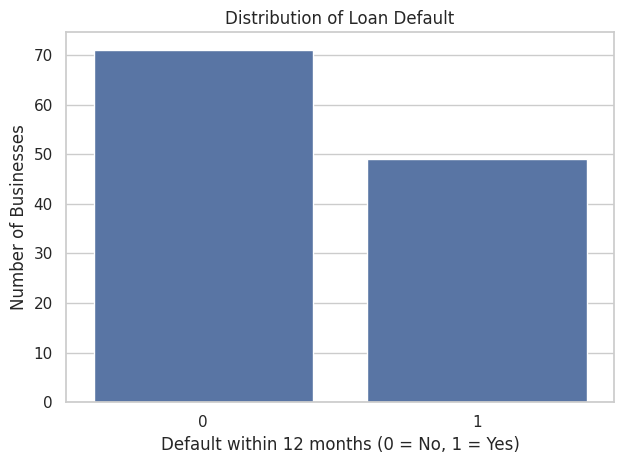

In [ ]:
#2
#Analyze the target variable

print(df["default_within_12m"].value_counts())

print("\nPercentage distribution:")
print(
    (df["default_within_12m"].value_counts(normalize=True) * 100)
    .round(2)
)

sns.countplot(data=df, x="default_within_12m")
plt.title("Distribution of Loan Default")
plt.xlabel("Default within 12 months (0 = No, 1 = Yes)")
plt.ylabel("Number of Businesses")
plt.tight_layout()
plt.show()


In [ ]:
#3
#Descriptive statistical analysis

numerical_cols = df.select_dtypes(include="number").columns

print(df[numerical_cols].describe().round(2).T)


                      count       mean        std       min        25%  \
annual_revenue_usd    120.0  480061.72  239853.83  31441.00  274835.50   
monthly_expenses_usd  120.0   23739.56   12415.78    970.94   13667.58   
requested_loan_usd    120.0   75833.37   45395.78   5769.00   31232.25   
business_age_years    120.0      12.32       7.56      0.00       5.75   
owner_credit_score    120.0     659.46     107.69    453.00     576.50   
late_payments_12m     120.0       1.27       1.16      0.00       0.00   
cash_reserves_usd     120.0   62040.63   34213.11   1535.00   35915.25   
industry              120.0       2.08       1.38      0.00       1.00   
monthly_transactions  120.0     870.26     490.56     35.00     478.25   
default_within_12m    120.0       0.41       0.49      0.00       0.00   

                            50%        75%        max  
annual_revenue_usd    479871.00  698200.00  878669.00  
monthly_expenses_usd   23739.56   33204.52   54231.42  
requested_loan_us

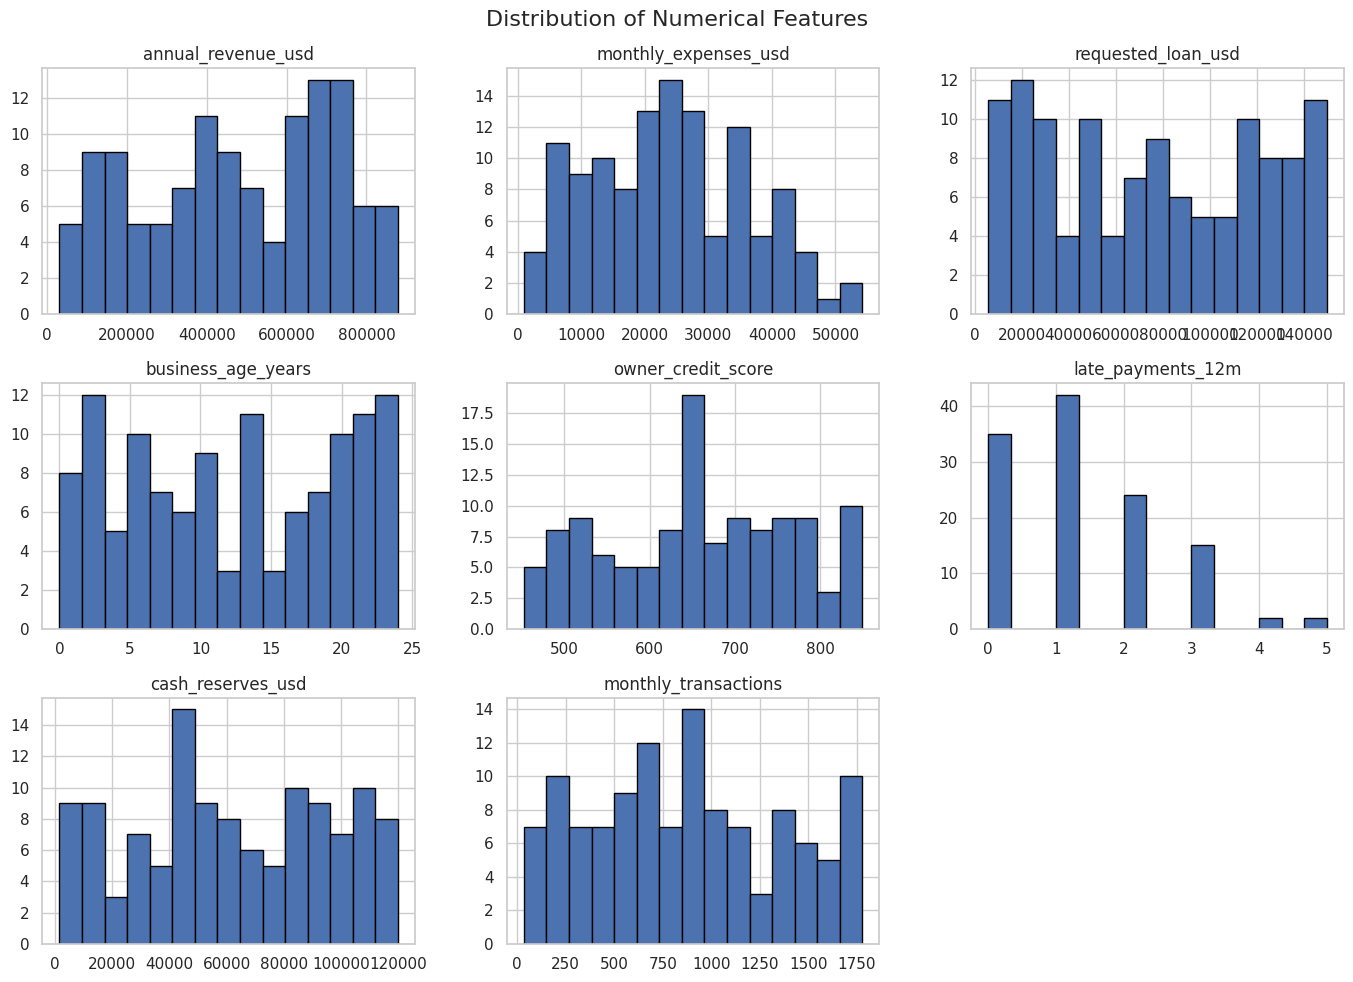

In [ ]:
#4
#Analyze numerical variables using histograms

numerical_cols = [
    "annual_revenue_usd",
    "monthly_expenses_usd",
    "requested_loan_usd",
    "business_age_years",
    "owner_credit_score",
    "late_payments_12m",
    "cash_reserves_usd",
    "monthly_transactions"
]

df[numerical_cols].hist(
    figsize=(14, 10),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


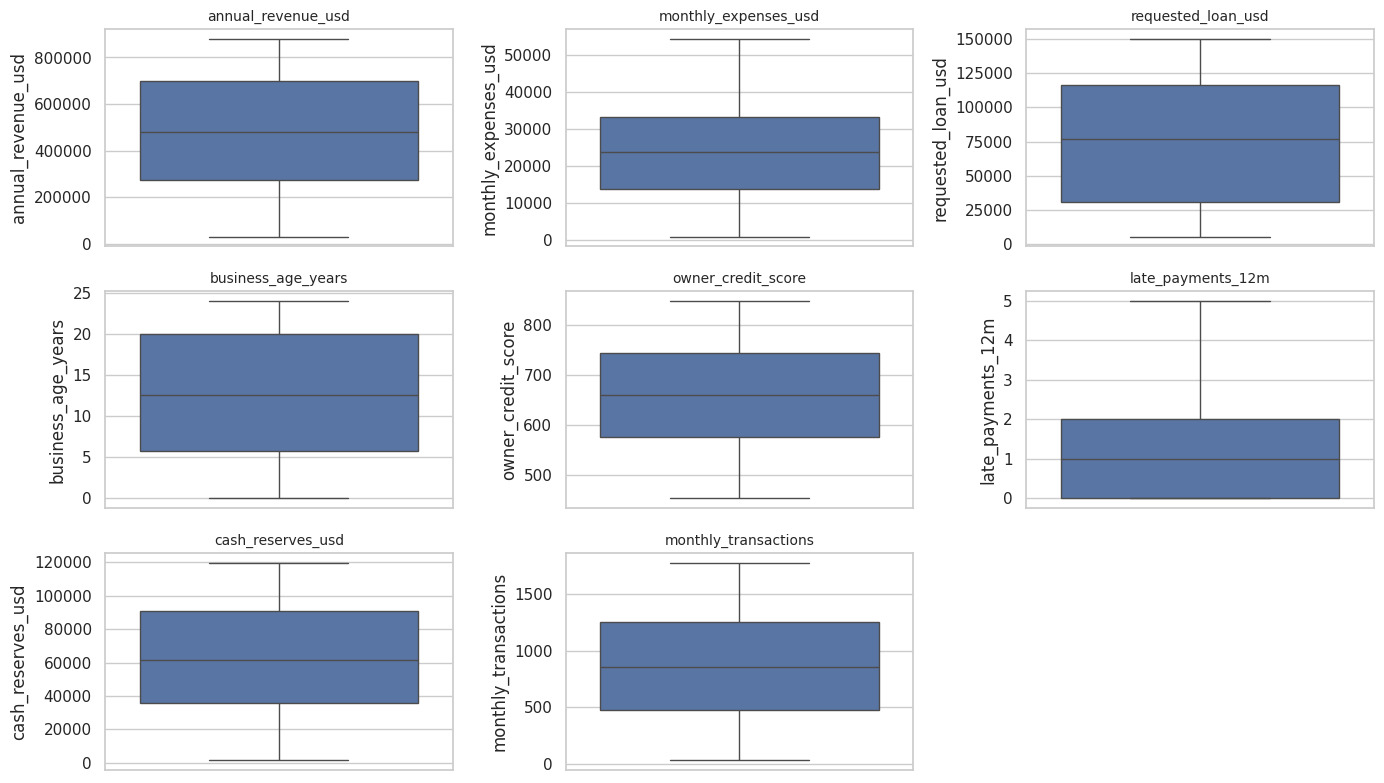

In [ ]:
#5
#Identify outliers using boxplots
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col])
    plt.title(col, fontsize=10)

plt.tight_layout()
plt.show()


Businesses by industry:
industry
1    29
2    27
3    24
4    20
0    17
5     3
Name: count, dtype: int64

Tax return availability:
tax_returns_available
Yes    97
No     23
Name: count, dtype: int64


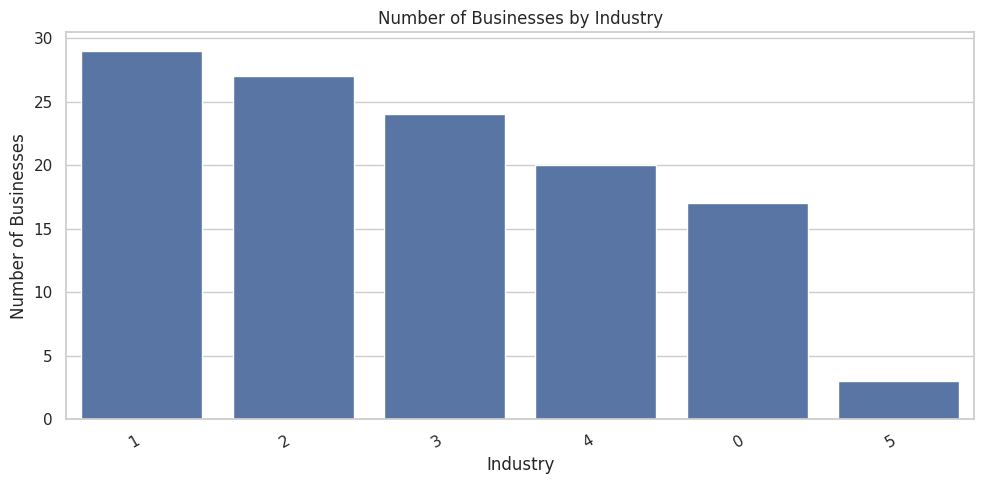

In [ ]:
#6
#Analyze categorical variables

print("Businesses by industry:")
print(df["industry"].value_counts())

print("\nTax return availability:")
print(df["tax_returns_available"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="industry",
    order=df["industry"].value_counts().index
)
plt.title("Number of Businesses by Industry")
plt.xlabel("Industry")
plt.ylabel("Number of Businesses")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Default rate by industry (%):
industry
0    47.06
1    34.48
2    55.56
3    29.17
4    40.00
5    33.33
Name: default_within_12m, dtype: float64


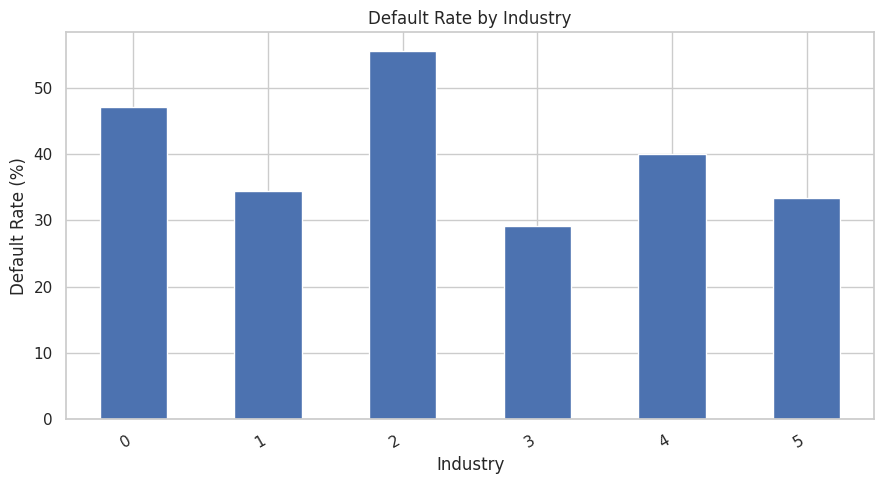


Default rate by tax return availability (%):
tax_returns_available
No     52.17
Yes    38.14
Name: default_within_12m, dtype: float64


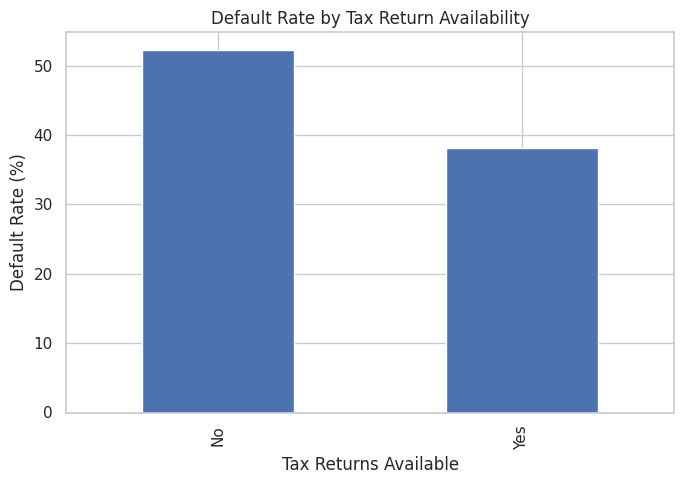

In [ ]:
#7
#Compare default rates across important features
industry_default = df.groupby(
    "industry",
    dropna=False
)["default_within_12m"].mean() * 100

print("Default rate by industry (%):")
print(industry_default.round(2))

industry_default.plot(kind="bar", figsize=(9, 5))
plt.title("Default Rate by Industry")
plt.xlabel("Industry")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


# Default rate by tax-return availability
tax_default = df.groupby(
    "tax_returns_available",
    dropna=False
)["default_within_12m"].mean() * 100

print("\nDefault rate by tax return availability (%):")
print(tax_default.round(2))

tax_default.plot(kind="bar", figsize=(7, 5))
plt.title("Default Rate by Tax Return Availability")
plt.xlabel("Tax Returns Available")
plt.ylabel("Default Rate (%)")
plt.tight_layout()
plt.show()


                      No Default (0)  Default (1)
annual_revenue_usd         472010.62    491727.59
monthly_expenses_usd        23015.75     24788.35
requested_loan_usd          72099.20     81244.10
business_age_years             13.28        10.92
owner_credit_score            699.55       601.37
late_payments_12m               1.11         1.51
cash_reserves_usd           62231.54     61764.02
monthly_transactions          856.55       890.13


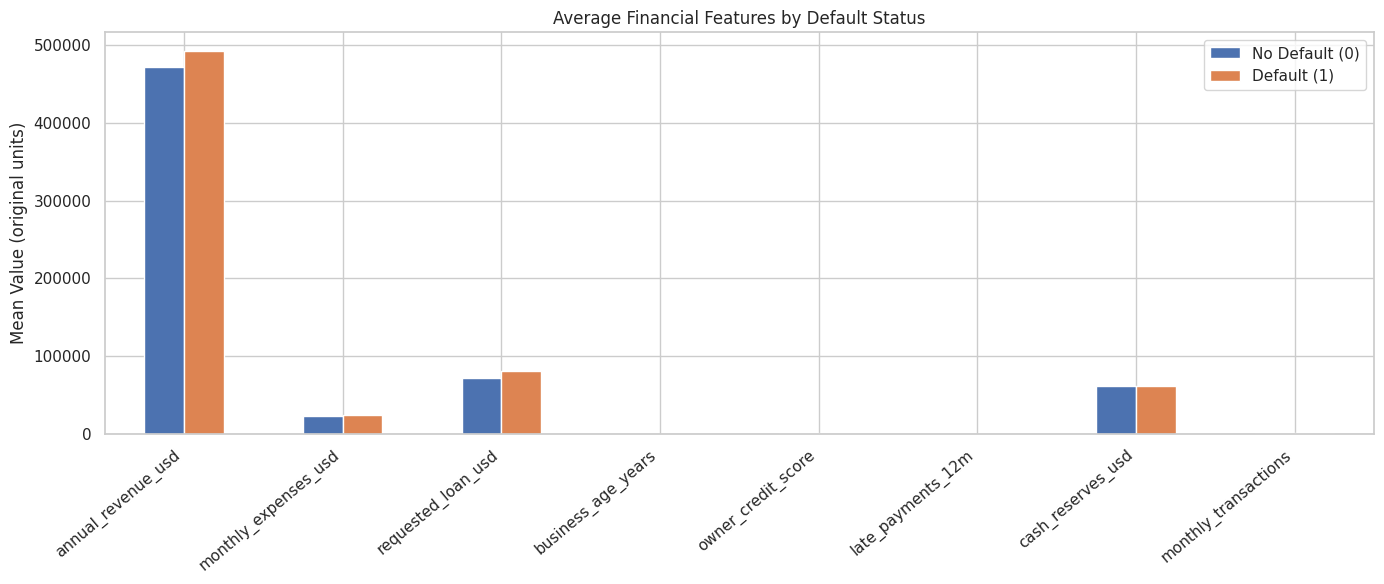

In [ ]:
#8
#Compare financial characteristics between default groups

features_to_compare = [
    "annual_revenue_usd",
    "monthly_expenses_usd",
    "requested_loan_usd",
    "business_age_years",
    "owner_credit_score",
    "late_payments_12m",
    "cash_reserves_usd",
    "monthly_transactions"
]

comparison = df.groupby("default_within_12m")[
    features_to_compare
].mean().T

comparison.columns = ["No Default (0)", "Default (1)"]

print(comparison.round(2))

comparison.plot(kind="bar", figsize=(14, 6))
plt.title("Average Financial Features by Default Status")
plt.ylabel("Mean Value (original units)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


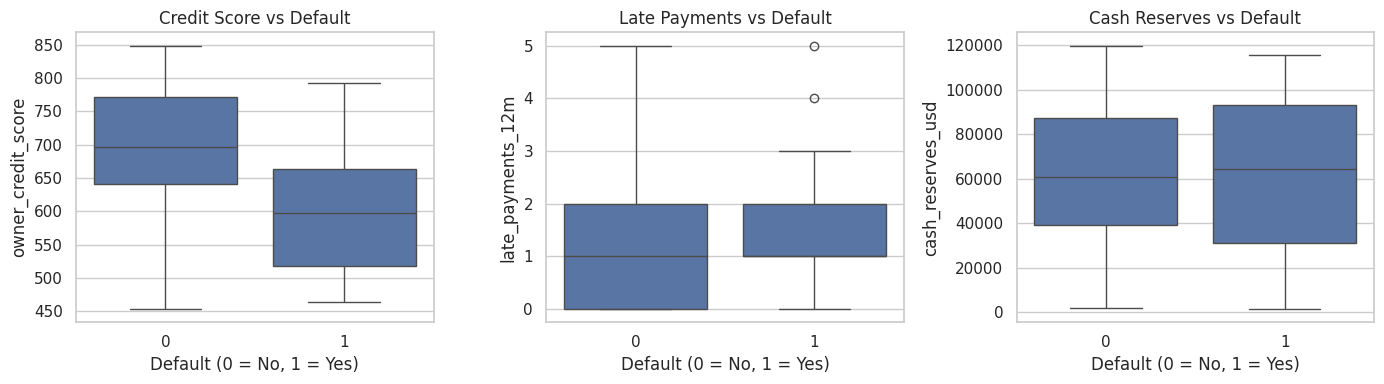

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(data=df, x="default_within_12m",
            y="owner_credit_score", ax=axes[0])
axes[0].set_title("Credit Score vs Default")

sns.boxplot(data=df, x="default_within_12m",
            y="late_payments_12m", ax=axes[1])
axes[1].set_title("Late Payments vs Default")

sns.boxplot(data=df, x="default_within_12m",
            y="cash_reserves_usd", ax=axes[2])
axes[2].set_title("Cash Reserves vs Default")

for ax in axes:
    ax.set_xlabel("Default (0 = No, 1 = Yes)")

plt.tight_layout()
plt.show()


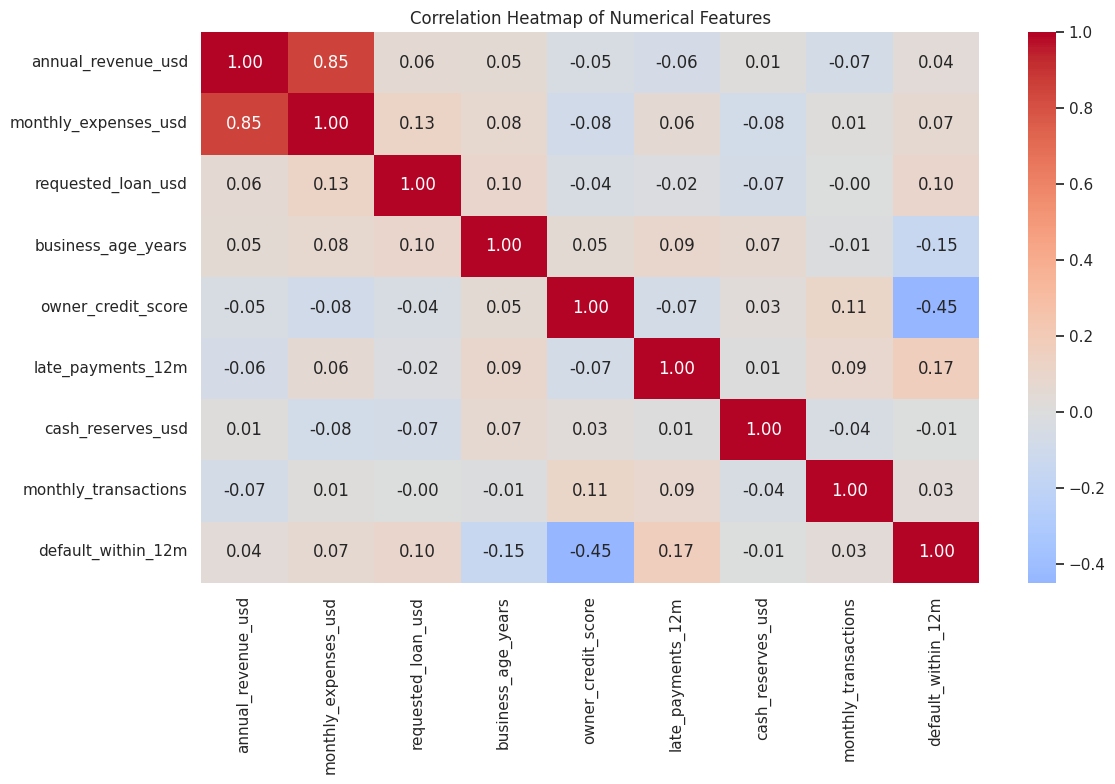


Correlation with default:
owner_credit_score     -0.450
business_age_years     -0.154
cash_reserves_usd      -0.007
monthly_transactions    0.034
annual_revenue_usd      0.041
monthly_expenses_usd    0.070
requested_loan_usd      0.099
late_payments_12m       0.169
Name: default_within_12m, dtype: float64


In [ ]:
#9
#Correlation analysis
corr_cols = numerical_cols + ["default_within_12m"]

correlation = df[corr_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

print("\nCorrelation with default:")
print(
    correlation["default_within_12m"]
    .drop("default_within_12m")
    .sort_values()
    .round(3)
)


In [ ]:

# STEP 5: Model Training

In [ ]:

# Step 2: Prepare features and target

import pandas as pd
import numpy as np

# Load the original dataset
df_model = pd.read_csv("creditworthiness_raw_sample.csv")

# Remove rows where the target is missing
df_model = df_model.dropna(subset=["default_within_12m"])

# X = input features; y = outcome to predict
X = df_model.drop(
    columns=["default_within_12m", "business_id"],
    errors="ignore"
)
y = df_model["default_within_12m"].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())


Features shape: (120, 10)
Target shape: (120,)

Target distribution:
default_within_12m
0    71
1    49
Name: count, dtype: int64


In [ ]:

# Step 3: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training features: (96, 10)
Testing features: (24, 10)
Training targets: (96,)
Testing targets: (24,)

Training target distribution:
default_within_12m
0    57
1    39
Name: count, dtype: int64

Testing target distribution:
default_within_12m
0    14
1    10
Name: count, dtype: int64


In [ ]:

# Step 4: Train all four machine learning models

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Preprocessing for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Define all four algorithms
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    )
}

# Train each model using the training data
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    print(name, "trained successfully!")

print("\nAll four models have been trained.")


Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
SVM trained successfully!

All four models have been trained.


In [ ]:

# Step 5: Compare all four models using 5-fold cross-validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results).set_index("Model")

display(cv_results_df.round(3))


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.696,0.666,0.568,0.603,0.769
Decision Tree,0.573,0.477,0.382,0.415,0.537
Random Forest,0.635,0.654,0.389,0.463,0.640
SVM,0.634,0.489,0.361,0.397,0.727


In [ ]:

# Step 6: Evaluate all four models on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from sklearn.pipeline import Pipeline

test_results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train on the training set
    pipeline.fit(X_train, y_train)

    # Predict on the unseen test set
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

test_results_df = pd.DataFrame(test_results).set_index("Model")

print("\nTest Set Comparison:")
display(test_results_df.round(3))



Logistic Regression
Confusion Matrix:
[[11  3]
 [ 3  7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        14
           1       0.70      0.70      0.70        10

    accuracy                           0.75        24
   macro avg       0.74      0.74      0.74        24
weighted avg       0.75      0.75      0.75        24


Decision Tree
Confusion Matrix:
[[13  1]
 [ 7  3]]

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.93      0.76        14
           1       0.75      0.30      0.43        10

    accuracy                           0.67        24
   macro avg       0.70      0.61      0.60        24
weighted avg       0.69      0.67      0.62        24


Random Forest
Confusion Matrix:
[[12  2]
 [ 7  3]]

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.86      0.73        14
   

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.750,0.70,0.7,0.700,0.707
Decision Tree,0.667,0.75,0.3,0.429,0.754
Random Forest,0.625,0.60,0.3,0.400,0.686
SVM,0.625,0.60,0.3,0.400,0.679


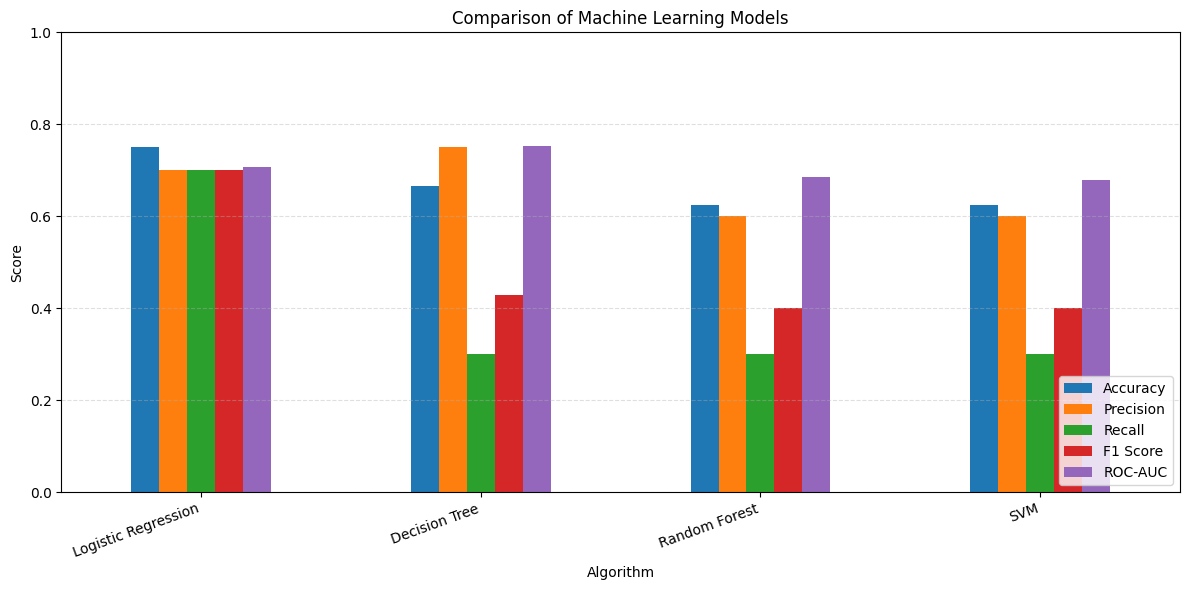

In [ ]:

# Step 7: Visual comparison of all four models

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

# Compare test-set performance
test_results_df[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()



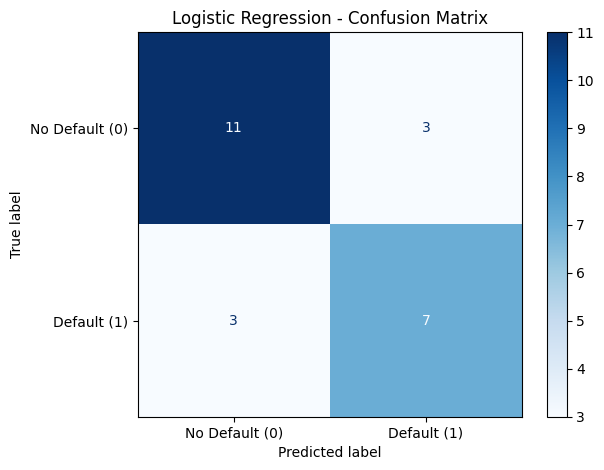

In [ ]:
# Step 7: Confusion Matrix Heatmap for Logistic Regression

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

# Train the selected model
best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["No Default (0)", "Default (1)"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()